# 1D One-Group Diffusion — Spherical Reactor
This notebook solves the one-group neutron diffusion equation in a 1D sphere geometry using the finite difference method. It calculates the fundamental mode and the effective multiplication factor $k_{eff}$.

The equation solved is:
$$ -D \nabla^2 \phi(r) + \Sigma_a \phi(r) = \frac{1}{k_{eff}} \nu \Sigma_f \phi(r) $$
with vacuum and symmetry boundary conditions (zero flux at the extrapolated boundary, zero derivative in the center).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
Avogadro = 6.02214076e23 # atoms/mol
rho = 15.61 # g/cm^3
A_Pu239 = 239 # g/mol
N_Pu239 = rho * Avogadro / (A_Pu239) * 1e-24 # Convert to atoms per b-cm

In [3]:
micro_abs = 2.11 # barns
micro_fission = 1.85
micro_tr = 6.8
#micro_capt = 0.26
nu = 2.98

In [4]:
Sigma_a = N_Pu239 * micro_abs
Sigma_f = N_Pu239 * micro_fission
Sigma_tr = N_Pu239 * micro_tr

In [5]:
R = 6.3849 # cm 
D = 1 / (3 * Sigma_tr)
R_ext = R + 2*D
N = 1000
dr = R_ext / (N)

## Analytical Solution

In [6]:
#A_1 = R_ext/(np.pi)
def phi(r):
    #phi_r = A_1*np.sin(np.pi * r / R_ext) / (r)
    phi_r = np.sinc(r / R_ext)  #sinc(x) = sin(pi*x)/(pi*x), and gives the correct value at r = 0
    return phi_r

In [7]:
keff_analytical = nu * Sigma_f / (D * (np.pi/R_ext)**2 + Sigma_a)

In [8]:
print(keff_analytical)

0.9070286862775472


In [9]:
r_i = (np.arange(N)+0.5)*dr

In [10]:
phi_i = []
for i in range(len(r_i)):
    phi_i.append(phi(r_i[i]))

## Numerical Solution

In [11]:
#Coefficients
a = []
b = []
c = []
for i in range(len(r_i)):
    a_i = -D/(dr**2*r_i[i]**2)*(r_i[i]-dr/2)**2
    b_i = Sigma_a + D/(dr**2*r_i[i]**2)*((r_i[i]+dr/2)**2 + (r_i[i]-dr/2)**2)
    c_i = -D/(dr**2*r_i[i]**2)*(r_i[i]+dr/2)**2
    a.append(a_i)
    b.append(b_i)
    c.append(c_i)

In [12]:
A = np.diag(b) + np.diag(c[:-1], 1) + np.diag(a[1:], -1)
A[-1, -1] -= c[-1] 

F_1 = np.eye(N) / (nu*Sigma_f)
eigvals, eigvecs = np.linalg.eig(F_1 @ A)
eigvals = eigvals.real
idx  = np.argmin(eigvals)
keff = 1 / eigvals[idx]
phi  = np.abs(eigvecs[:, idx].real); phi /= phi.max()
print(f"k_eff = {keff:.5f}")

k_eff = 0.90703


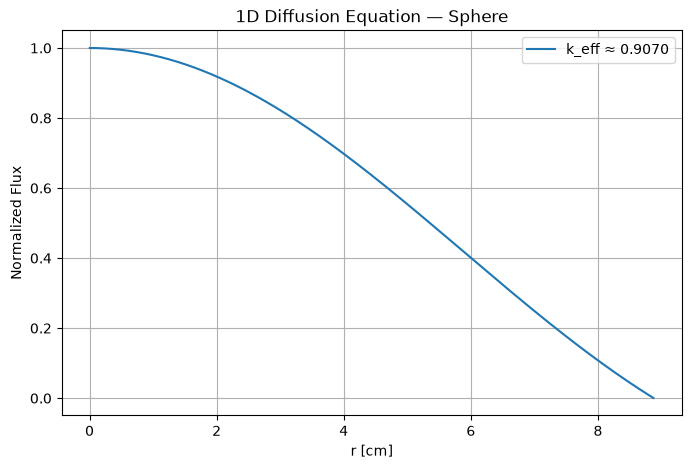

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(r_i, phi, label=f'k_eff ≈ {keff:.4f}')
plt.xlabel('r [cm]')
plt.ylabel('Normalized Flux')
plt.title('1D Diffusion Equation — Sphere')
plt.grid(True)
plt.legend()
plt.show()

## Comparing Solutions

### Numerical x Analytical

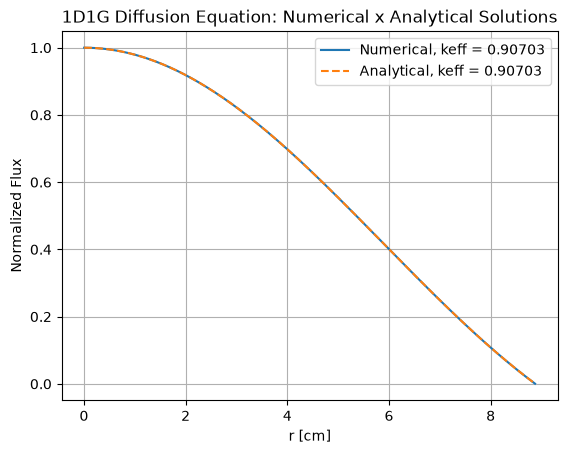

In [14]:
plt.figure()
plt.plot(r_i, phi, label=f'Numerical, keff = {keff:.5f}')
plt.plot(r_i, phi_i, '--', label=f'Analytical, keff = {keff_analytical:.5f}')
plt.xlabel('r [cm]')
plt.ylabel('Normalized Flux')
plt.title('1D1G Diffusion Equation: Numerical x Analytical Solutions')
plt.grid(True)
plt.legend()
plt.show()

### Diffusion x OpenMC

In [15]:
r_grid = np.linspace(0, R, 6)

In [16]:
import openmc

In [17]:
sp = openmc.StatePoint('statepoint.200.h5', autolink=False)
keff_mc = sp.keff   # separate name so the diffusion keff isn't overwritten
flux_tally = sp.tallies[1]
sp.close()

In [18]:
rho_analytical = (keff_analytical-1)/keff_analytical*1e5 #pcm
rho_numerical = (keff-1)/keff*1e5 #pcm
rho_mc = (keff_mc-1)/keff_mc*1e5 #pcm

In [19]:
rho_numerical-rho_analytical

np.float64(-0.018234913721244084)

In [20]:
print(rho_analytical-rho_mc)
print(rho_numerical-rho_mc)

-10209+/-15
-10209+/-15


In [21]:
print(keff_mc)

0.99959+/-0.00015


In [22]:
volumes = []
for i in range(1, len(r_grid)):
    volumes.append((4/3) * np.pi * (r_grid[i]**3 - r_grid[i-1]**3))
flux = flux_tally.mean.ravel() / volumes
r_mid = 0.5 * (r_grid[1:] + r_grid[:-1])   # shell midpoints instead of outer edges

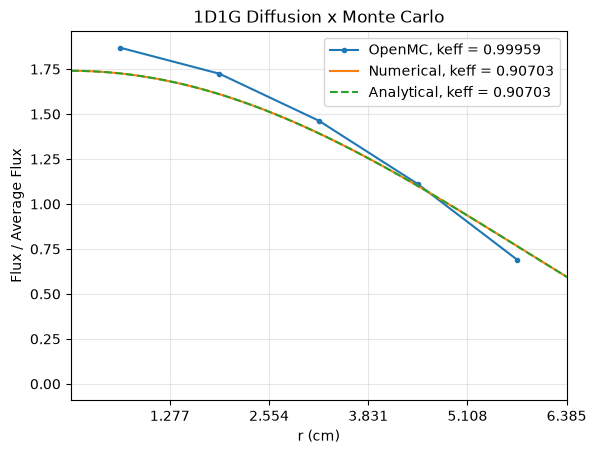

In [23]:
V = 4/3 * np.pi * R**3
w = r_i**2 * (r_i <= R)
phi_i = np.array(phi_i)

mc_avg = flux_tally.mean.sum() / V
phi_avg = np.sum(phi * w) / np.sum(w)
phi_i_avg = np.sum(phi_i * w) / np.sum(w)

plt.plot(r_mid, flux / mc_avg, '.-', label=f'OpenMC, keff = {keff_mc.n:.5f}')
plt.plot(r_i, phi / phi_avg, label=f'Numerical, keff = {keff:.5f}')
plt.plot(r_i, phi_i / phi_i_avg, '--', label=f'Analytical, keff = {keff_analytical:.5f}')
plt.xlabel('r (cm)')
plt.ylabel('Flux / Average Flux')
plt.xticks(np.linspace(0, R, 6)[1:])
plt.xlim(0, R)
plt.title('1D1G Diffusion x Monte Carlo')
plt.grid(alpha=0.3)
plt.legend()
plt.show()